In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("GeoPulse - Data Quality and EDA")
print("Libraries imported successfully!")

GeoPulse - Data Quality and EDA
Libraries imported successfully!


In [2]:
gps = pd.read_csv("../data/geopulse_gps_data.csv")

print("GPS Dataset Loaded Successfully")

FileNotFoundError: [Errno 2] No such file or directory: '../data/geopulse_gps_data.csv'

In [3]:
import os

print(os.getcwd())

C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics


In [4]:
gps = pd.read_csv("data/geopulse_gps_data.csv")

print("GPS Dataset Loaded Successfully!")

GPS Dataset Loaded Successfully!


In [5]:
gps.head()

,DeviceID,Lat,Long,Timestamp
0,D001,28.637454,77.104714,2026-11-01 00:00:00
1,D002,28.695071,77.195462,2026-11-01 01:00:00
2,D003,28.673199,77.147153,2026-11-01 02:00:00
3,D004,28.659866,77.176286,2026-11-01 03:00:00
4,D005,28.615602,77.236135,2026-11-01 04:00:00


In [6]:
gps.shape

(100, 4)

In [7]:
gps.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   DeviceID   100 non-null    str    
 1   Lat        100 non-null    float64
 2   Long       100 non-null    float64
 3   Timestamp  100 non-null    str    
dtypes: float64(2), str(2)
memory usage: 3.3 KB


In [8]:
gps.isnull().sum()

DeviceID     0
Lat          0
Long         0
Timestamp    0
dtype: int64

In [9]:
# Check duplicate records

duplicates = gps.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 0


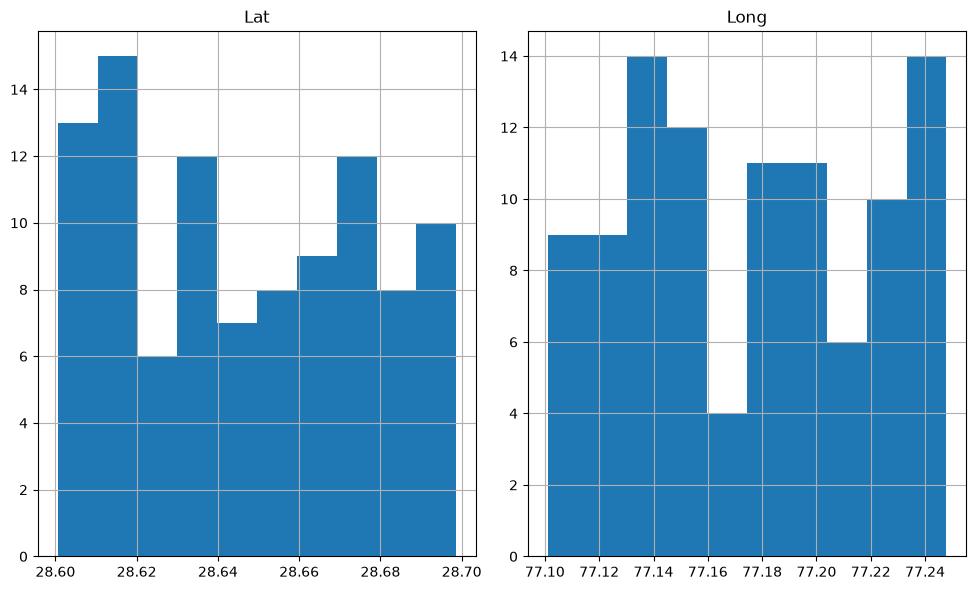

In [10]:
import matplotlib.pyplot as plt

gps.hist(figsize=(10, 6))

plt.tight_layout()
plt.show()

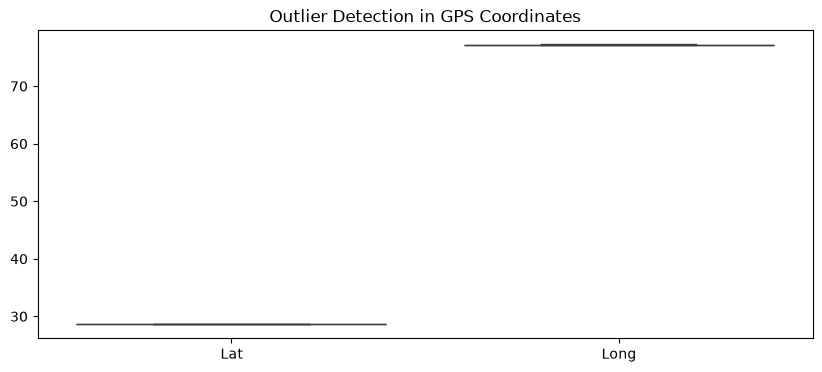

In [11]:
# Check outliers using Boxplot

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

sns.boxplot(data=gps[['Lat', 'Long']])

plt.title("Outlier Detection in GPS Coordinates")
plt.show()

In [12]:
# Statistical Summary of GPS Dataset

gps.describe()

,Lat,Long
count,100.000000,100.000000
mean,28.647018,77.174675
std,0.029749,0.043967
min,28.600552,77.101043
25%,28.619320,77.136301
50%,28.646414,77.175844
75%,28.673020,77.214928
max,28.698689,77.247848


           Lat      Long
Lat   1.000000 -0.034033
Long -0.034033  1.000000


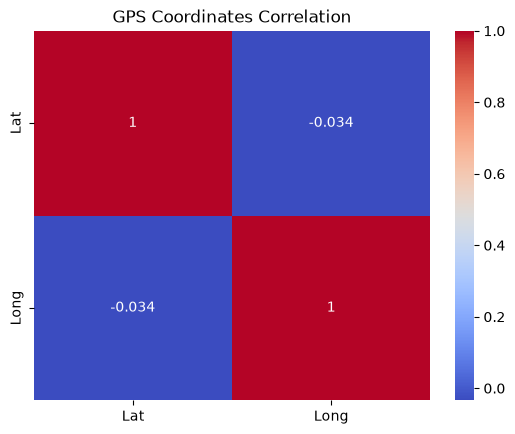

In [13]:
# Correlation Analysis

correlation = gps[['Lat', 'Long']].corr()

print(correlation)

sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title("GPS Coordinates Correlation")
plt.show()

In [14]:
# Date and Time Analysis

gps['Timestamp'] = pd.to_datetime(gps['Timestamp'])

print("First Timestamp:", gps['Timestamp'].min())
print("Last Timestamp:", gps['Timestamp'].max())

print("Total Time Period:",
      gps['Timestamp'].max() - gps['Timestamp'].min())

First Timestamp: 2026-11-01 00:00:00
Last Timestamp: 2026-11-05 03:00:00
Total Time Period: 4 days 03:00:00


In [15]:
# Device-wise GPS Record Count

device_counts = gps['DeviceID'].value_counts()

print(device_counts)

DeviceID
D001    1
D002    1
D003    1
D004    1
D005    1
       ..
D096    1
D097    1
D098    1
D099    1
D100    1
Name: count, Length: 100, dtype: int64


In [16]:
# Count Unique Devices

unique_devices = gps['DeviceID'].nunique()

print("Total Unique Devices:", unique_devices)

Total Unique Devices: 100


In [2]:
import geopy
from geopy.distance import geodesic

print("GeoPy:", geopy.__version__)
print("GeoPy installation successful!")

GeoPy: 2.5.0
GeoPy installation successful!


In [3]:
libraries = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "geopy"
]

for library in libraries:
    module = __import__(library)
    print(f"{library}: {module.__version__}")

pandas: 3.0.3
numpy: 2.4.6
matplotlib: 3.11.0
seaborn: 0.13.2
geopy: 2.5.0


In [6]:
import sys

sys.path.insert(0, "src")

from geopulse.config import PROJECT_ROOT, GPS_DATA_PATH
from geopulse.data_loader import load_gps_data
from geopulse.validation import validate_gps_data

print("Project Root:", PROJECT_ROOT)
print("GPS Dataset:", GPS_DATA_PATH)

gps = load_gps_data()

print("\nDataset Shape:", gps.shape)
print("\nValidation Results:")
print(validate_gps_data(gps))

Project Root: C:\Users\visha\Desktop\GeoPulse--Hyper-Local-Retail-Mobility-Analytics
GPS Dataset: C:\Users\visha\Desktop\GeoPulse--Hyper-Local-Retail-Mobility-Analytics\data\geopulse_gps_data.csv

Dataset Shape: (100, 4)

Validation Results:
{'missing_columns': [], 'missing_values': {'DeviceID': 0, 'Lat': 0, 'Long': 0, 'Timestamp': 0}, 'duplicate_rows': 0, 'invalid_latitudes': 0, 'invalid_longitudes': 0}


In [8]:
from geopulse.data_loader import load_gps_data
from geopulse.validation import validate_gps_data

gps = load_gps_data()

print("Original Dataset Validation:")
print(validate_gps_data(gps))

Original Dataset Validation:
{'missing_columns': [], 'missing_values': {'DeviceID': 0, 'Lat': 0, 'Long': 0, 'Timestamp': 0}, 'duplicate_rows': 0, 'invalid_latitudes': 0, 'invalid_longitudes': 0}


In [12]:
import importlib
import geopulse.validation

importlib.reload(geopulse.validation)

from geopulse.validation import validate_gps_data


In [13]:
test_gps = gps.copy()

test_gps = test_gps.astype({
    "Lat": "object",
    "Long": "object",
    "Timestamp": "object",
    "DeviceID": "object"
})

test_gps.loc[test_gps.index[0], "Lat"] = "invalid"
test_gps.loc[test_gps.index[1], "Long"] = 200
test_gps.loc[test_gps.index[2], "Timestamp"] = "wrong-date"
test_gps.loc[test_gps.index[3], "DeviceID"] = "   "

print("Test Dataset Validation:")
print(validate_gps_data(test_gps))

Test Dataset Validation:
{'missing_columns': [], 'missing_values': {'DeviceID': 0, 'Lat': 0, 'Long': 0, 'Timestamp': 0}, 'duplicate_rows': 0, 'non_numeric_latitudes': 1, 'invalid_latitudes': 0, 'non_numeric_longitudes': 0, 'invalid_longitudes': 1, 'invalid_timestamps': 1, 'empty_device_ids': 1}


In [14]:
print("Original GPS Dataset Validation:")
print(validate_gps_data(gps))

print("\nOriginal Dataset Shape:", gps.shape)
print("Test Dataset Shape:", test_gps.shape)

Original GPS Dataset Validation:
{'missing_columns': [], 'missing_values': {'DeviceID': 0, 'Lat': 0, 'Long': 0, 'Timestamp': 0}, 'duplicate_rows': 0, 'non_numeric_latitudes': 0, 'invalid_latitudes': 0, 'non_numeric_longitudes': 0, 'invalid_longitudes': 0, 'invalid_timestamps': 0, 'empty_device_ids': 0}

Original Dataset Shape: (100, 4)
Test Dataset Shape: (100, 4)


In [15]:
from geopulse.data_loader import load_store_data, load_catchment_data

stores = load_store_data()
catchment = load_catchment_data()

print("Store Dataset:")
print("Shape:", stores.shape)
print("Columns:", stores.columns.tolist())
display(stores.head())

print("\nExisting Catchment Dataset:")
print("Shape:", catchment.shape)
print("Columns:", catchment.columns.tolist())
display(catchment.head())

Store Dataset:
Shape: (5, 4)
Columns: ['StoreID', 'StoreName', 'Lat', 'Long']


,StoreID,StoreName,Lat,Long
0,S001,Store A,28.65,77.15
1,S002,Store B,28.67,77.18
2,S003,Store C,28.63,77.20
3,S004,Store D,28.69,77.12
4,S005,Store E,28.61,77.23



Existing Catchment Dataset:
Shape: (5, 3)
Columns: ['StoreID', 'StoreName', 'Devices_Within_500m']


,StoreID,StoreName,Devices_Within_500m
0,S001,Store A,1
1,S002,Store B,0
2,S003,Store C,1
3,S004,Store D,1
4,S005,Store E,1


In [16]:
from geopulse.catchment import analyze_catchments

distances, catchment_results = analyze_catchments(
    gps,
    stores
)

print("Distance Analysis Shape:", distances.shape)

print("\nDistance Analysis Sample:")
display(distances.head(10))

print("\nCatchment Analysis Results:")
display(catchment_results)

Distance Analysis Shape: (500, 5)

Distance Analysis Sample:


,DeviceID,StoreID,StoreName,Distance_Meters,Within_Catchment
0,D001,S001,Store A,4640.83,False
1,D001,S002,Store B,8196.43,False
2,D001,S003,Store C,9353.62,False
3,D001,S004,Store D,6012.32,False
4,D001,S005,Store E,12623.82,False
5,D002,S001,Store A,6685.70,False
6,D002,S002,Store B,3163.01,False
7,D002,S003,Store C,7225.51,False
8,D002,S004,Store D,7395.93,False
9,D002,S005,Store E,10014.86,False



Catchment Analysis Results:


,StoreID,StoreName,Devices_Within_500m
0,S001,Store A,1
1,S002,Store B,0
2,S003,Store C,1
3,S004,Store D,1
4,S005,Store E,1


# Existing results se comparison

In [17]:
comparison = catchment.merge(
    catchment_results,
    on=["StoreID", "StoreName"],
    suffixes=("_Existing", "_Calculated")
)

comparison["Match"] = (
    comparison["Devices_Within_500m_Existing"]
    == comparison["Devices_Within_500m_Calculated"]
)

display(comparison)

print("\nAll Results Match:", comparison["Match"].all())

,StoreID,StoreName,Devices_Within_500m_Existing,Devices_Within_500m_Calculated,Match
0,S001,Store A,1,1,True
1,S002,Store B,0,0,True
2,S003,Store C,1,1,True
3,S004,Store D,1,1,True
4,S005,Store E,1,1,True



All Results Match: True


In [18]:
display(comparison)

print("All Results Match:", comparison["Match"].all())

,StoreID,StoreName,Devices_Within_500m_Existing,Devices_Within_500m_Calculated,Match
0,S001,Store A,1,1,True
1,S002,Store B,0,0,True
2,S003,Store C,1,1,True
3,S004,Store D,1,1,True
4,S005,Store E,1,1,True


All Results Match: True
